# Практическое занятие 1. Рабочее окружение

In [ ]:
student = "Кузовков Даниил Романович"   # Фамилия Имя Отчество
group = "251-952"     # номер группы
likely_citation = "" # любимая или прикольная цитата
link_meme = "" # ссылка на любимый мем (в пределах цензуры)
print(student, group, likely_citation, link_meme)

**Основные ссылки.** Полный перечень ресурсов приведен в конце ноутбука.

| Ресурс | Адрес |
|---|---|
| Документация uv | https://docs.astral.sh/uv/ |
| Документация pip | https://pip.pypa.io/en/stable/ |
| Pro Git (на русском) | https://git-scm.com/book/ru/v2 |
| Документация Jupyter в VS Code | https://code.visualstudio.com/docs/datascience/jupyter-notebooks |

## 0. Работа с ноутбуком

Ноутбук состоит из ячеек двух типов: **Code** (код; результат выводится под ячейкой) и **Markdown** (текст). Ход занятия фиксируется в этом файле: команды, результаты выполнения, скриншоты.

**Цель.** Научиться выполнять ячейки ноутбука, вставлять скриншоты и определять среду выполнения.

Ноутбук объединяет текст, код и результаты в одном файле и служит рабочим журналом занятия. Умение работать с ячейками и перезапускать выполнение необходимо на всех последующих занятиях курса.

| Действие | Colab | VS Code |
|---|---|---|
| Выполнить ячейку и перейти к следующей | Shift + Enter | Shift + Enter |
| Выполнить все ячейки | Runtime → Run all | кнопка Run All на панели ноутбука |
| Перезапустить среду выполнения | Runtime → Restart session | кнопка Restart на панели ноутбука |
| Добавить ячейку | + Code, + Text | + Code, + Markdown |
| Сохранить | автоматически; скачать: File → Download → .ipynb | Ctrl + S (macOS: Cmd + S) |


| Среда | Что это | Особенность |
|---|---|---|
| Google Colab | облачная среда: ноутбук выполняется на сервере Google (Linux) | среда временная: файлы удаляются при отключении; нужен только браузер и аккаунт Google |
| VS Code / локальная IDE | программа на своем компьютере | файлы остаются на компьютере; требуется установка Python и расширений |



**Вставка скриншота.** Дважды щелкнуть по ячейке «Скриншот», нажать Ctrl + V (macOS: Cmd + V), выполнить ячейку (Shift + Enter).

**Работа с командами.** Команды, которые запускаются ячейками этого ноутбука, затем повторно выполняются вручную на своем компьютере в терминале. Под каждой такой ячейкой расположена ячейка для скриншота результата ручного выполнения. Терминал открывается в корне проекта `lab1`.

| ОС | Как открыть терминал |
|---|---|
| Windows | Win + R, ввести `cmd`, Enter; затем перейти в папку проекта командой `cd` |
| macOS | программа «Терминал» (Spotlight: Cmd + Пробел) |
| VS Code (все ОС) | Terminal → New Terminal (Ctrl + `); терминал открывается в папке проекта |

**0.1. Определить среду выполнения и задать функцию запуска команд.**

In [1]:
import os, sys, platform, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
WINDOWS = platform.system() == "Windows"

# Рабочая папка: корень занятия lab1 (если ноутбук лежит в lab1/notebooks) или текущая папка.
# COURSE — папка дисциплины (work): в ней живет Git, а lab1 — папка внутри репозитория.
cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
COURSE = ROOT.parent if ROOT.name == "lab1" else ROOT
os.chdir(ROOT)

def venv_python(env):
    # Путь к программе Python внутри виртуального окружения
    return Path(env) / ("Scripts" if WINDOWS else "bin") / ("python.exe" if WINDOWS else "python")

VENV_PY = venv_python(ROOT / ".venv")         # окружение проекта (блок 5)
UVENV_PY = venv_python(ROOT / ".venv-uv")     # окружение, созданное uv (блок 6)
UV = f'"{VENV_PY}" -m uv'                     # запуск uv из окружения проекта

def sh(command, cwd=None, local=False):
    # Выполняет команду в оболочке системы и выводит результат.
    # Оболочка: cmd (Windows) или bash (macOS, Linux). Рабочая папка: ROOT или cwd.
    # local=True: команда выполняется только на своем компьютере.
    if local and IN_COLAB:
        print("Пропущено:", command)
        return
    if not command.strip():
        print("Команда не указана")
        return
    if cwd and not Path(cwd).exists():
        print("Папка не найдена:", cwd)
        return
    if WINDOWS:
        command = "chcp 65001 >nul && " + command
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    try:
        r = subprocess.run(command, shell=True, cwd=cwd or ROOT, env=env, capture_output=True,
                           text=True, encoding="utf-8", errors="replace",
                           stdin=subprocess.DEVNULL, timeout=600)
    except subprocess.TimeoutExpired:
        print("Команда не завершилась за 10 минут")
        return
    print(r.stdout + r.stderr, end="")
    if r.returncode:
        print("Код завершения:", r.returncode)

print("Python:", sys.version.split()[0])
print("Система:", platform.system())
print("Colab:", IN_COLAB)
print("Рабочая папка:", ROOT)
print("Папка дисциплины:", COURSE)

Python: 3.14.0
Система: Darwin
Colab: False
Рабочая папка: /Users/daniil/Desktop/work/lab1
Папка дисциплины: /Users/daniil/Desktop/work


#В этой ячейке необходимо интерпретировать полученный вывод прошлой ячейки "code". Для этого удалите этот текст и введите свой, обычным шрифтом

## 1. Аккаунты и сервисы

**Цель.** Подготовить аккаунты, которые используются на всех занятиях курса.

**Зачем это нужно.** Аккаунт GitHub необходим для хранения проектов и сдачи работ, аккаунт Google – для запуска ноутбука в облаке.

| Сервис | Для чего | Адрес |
|---|---|---|
| GitHub | хранение проектов и истории изменений, публикация работ | https://github.com/|
| Аккаунт Google | вход в Colab | https://accounts.google.com/ |
| Google Colab | запуск ноутбуков в браузере | https://colab.research.google.com/ |

**Порядок регистрации.** Зарегистрироваться на GitHub и выбрать бесплатный тариф (Free).

**1.1. Записать имя пользователя GitHub и вывести адрес профиля.**

In [2]:
github_username = "Dan-117777"   # имя пользователя GitHub
print(f"https://github.com/{github_username}")

https://github.com/Dan-117777


**Скриншот.** Вставить скрин страницы профиля GitHub: видны имя пользователя и адрес в адресной строке браузера.
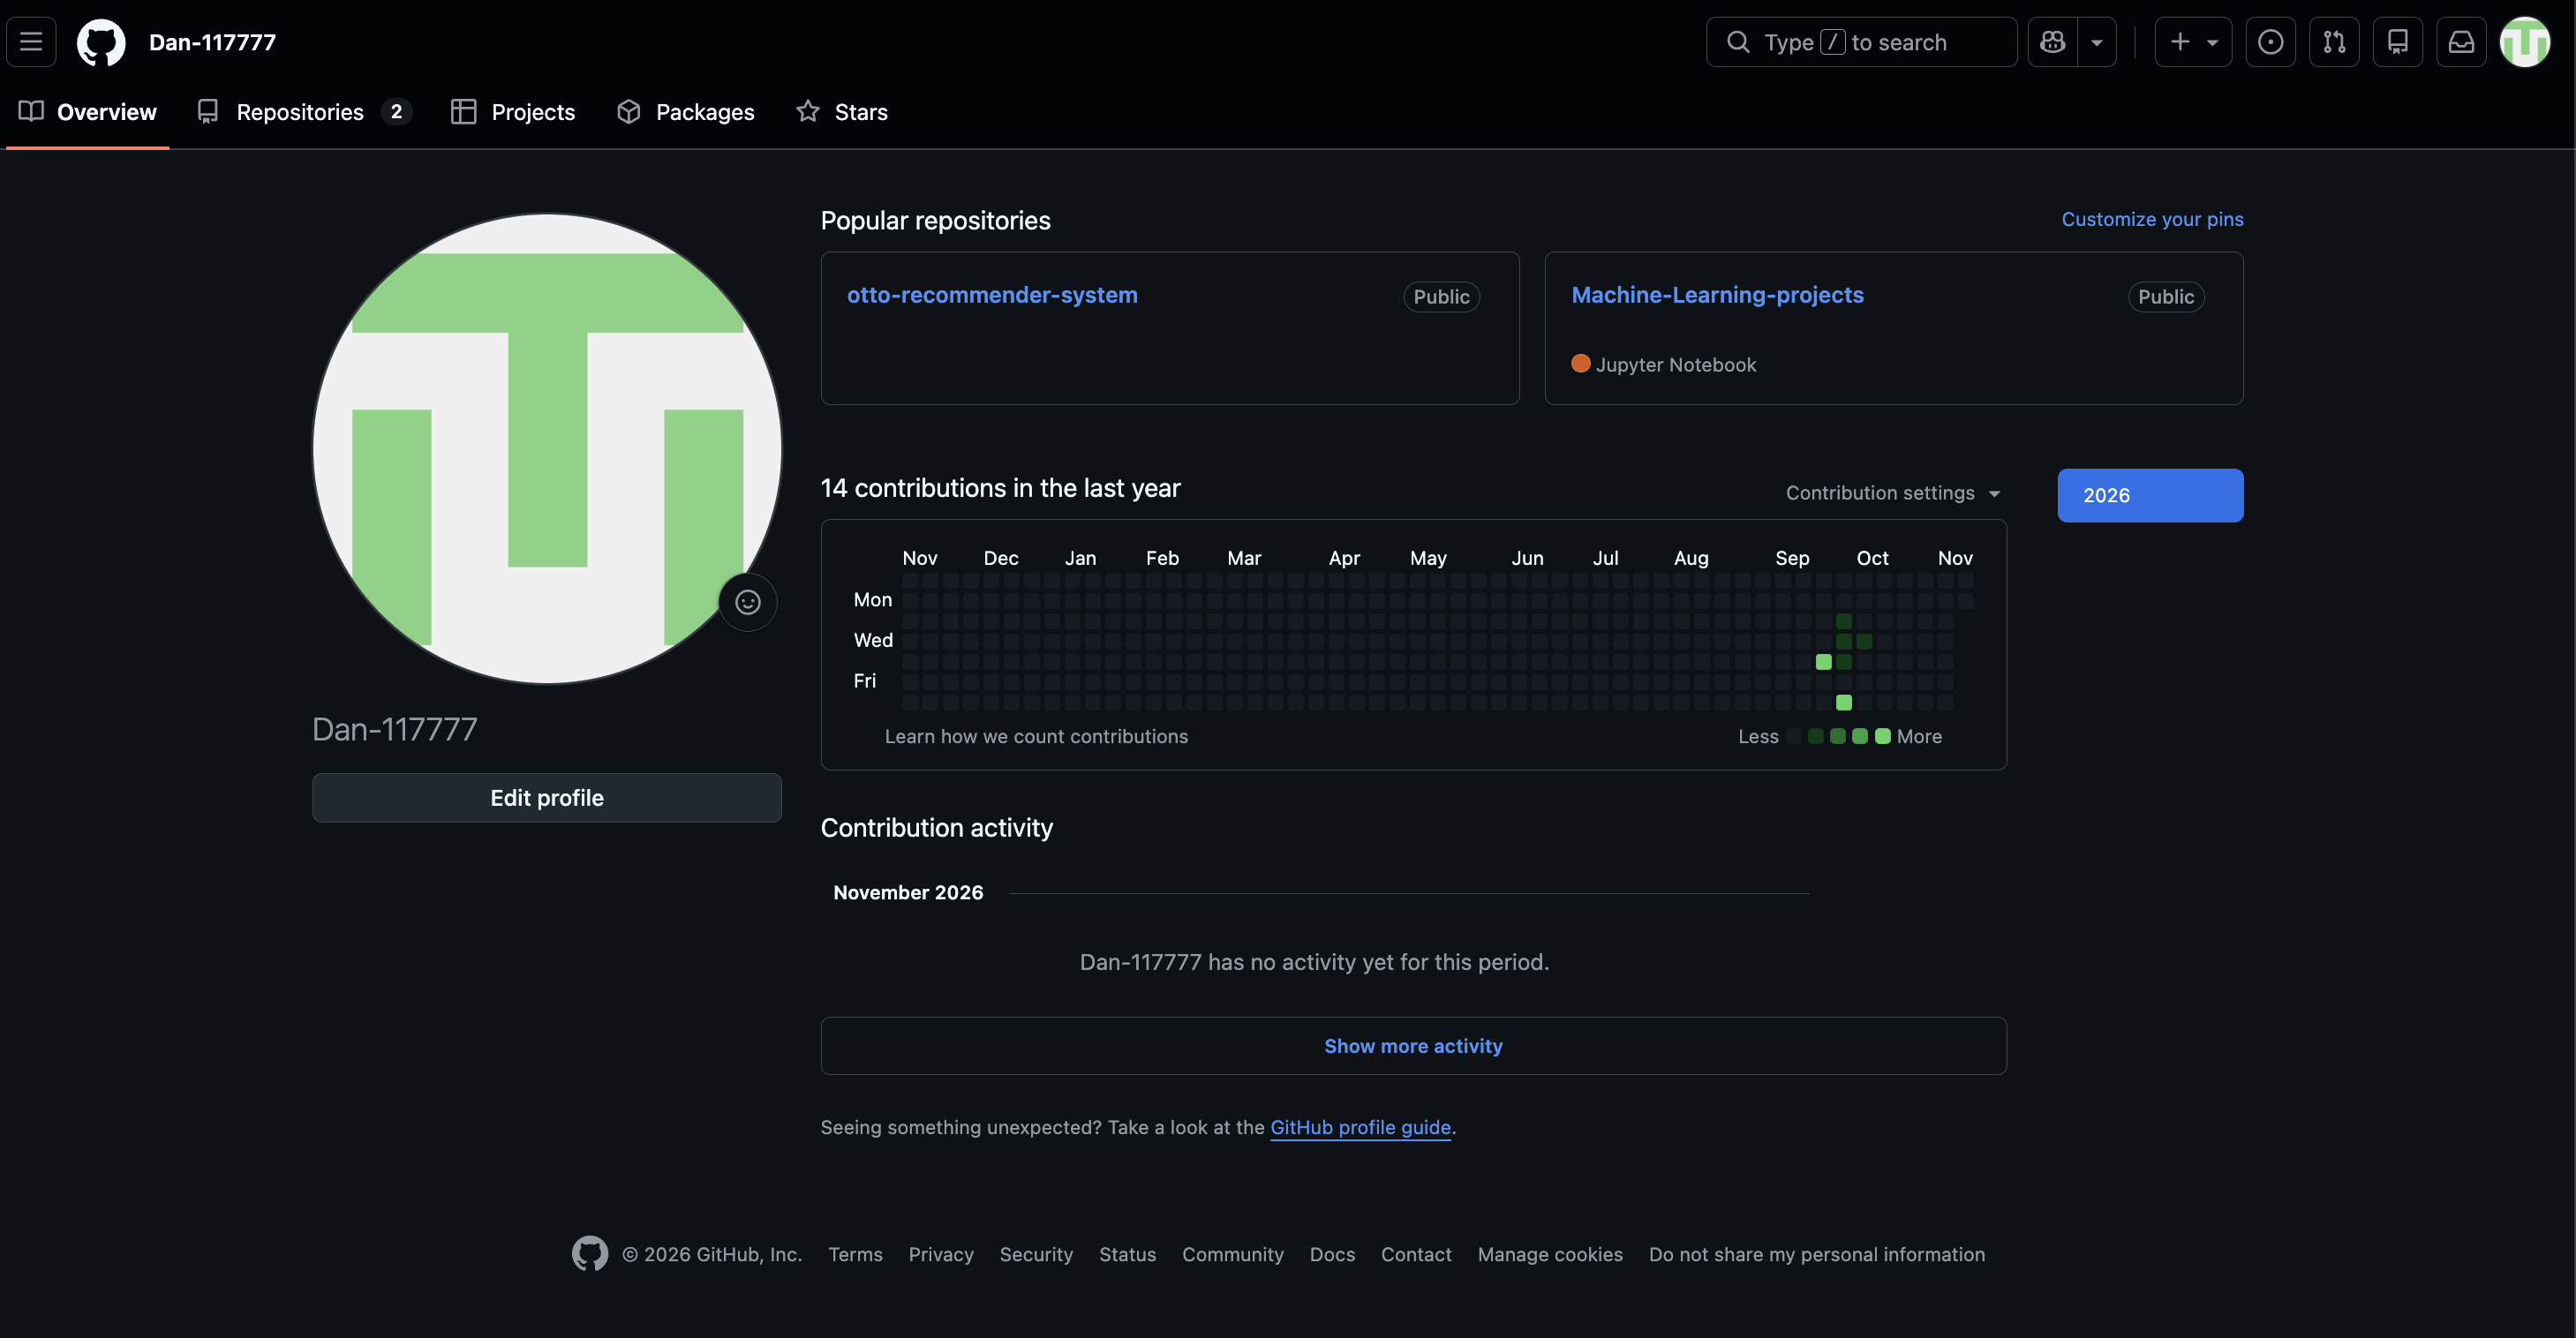

## 2. Установка программ и перенос ноутбука в VS Code

**Цель.** Установить программы разработчика, перенести этот ноутбук в проект `lab1` и продолжить работу в VS Code.

Работа над проектом ведется на своем компьютере: файлы остаются у разработчика, а ноутбук запускается в окружении проекта. Python, Git и VS Code составляют минимальный набор инструментов, на котором строятся все следующие занятия.

| Программа | Назначение | Адрес | Особенность установки |
|---|---|---|---|
| Python 3.12 | язык программирования, на котором выполняются ячейки | https://www.python.org/downloads/ | Windows: на первом экране отметить **Add python.exe to PATH** |
| Git | система контроля версий | https://git-scm.com/downloads | Windows: параметры по умолчанию; macOS: при первом вызове `git` система предложит установить средства разработчика, согласиться |
| VS Code | редактор кода с поддержкой ноутбуков | https://code.visualstudio.com/ | установить расширения Python и Jupyter (издатель Microsoft) |

| Элемент VS Code | Назначение |
|---|---|
| Расширение Python | поддержка языка Python |
| Расширение Jupyter | работа с ноутбуками `.ipynb` |
| Explorer (слева) | файлы и папки проекта |
| Select Kernel (справа вверху в ноутбуке) | выбор окружения, в котором выполняется код ячеек |

| Действие | Windows и Linux | macOS |
|---|---|---|
| Панель расширений | Ctrl + Shift + X | Cmd + Shift + X |
| Палитра команд | Ctrl + Shift + P | Cmd + Shift + P |
| Сохранить файл | Ctrl + S | Cmd + S |

Документация по ноутбукам в VS Code: https://code.visualstudio.com/docs/datascience/jupyter-notebooks

**2.1. Скопировать ноутбук в проект.**

Перед выполнением открыть выданный файл ноутбука в VS Code (File → Open File), выбрать ядро (Select Kernel → Python Environments → Python 3.12. Если VS Code предложит установить ipykernel - согласиться и сохранить файл (Ctrl + S). 

После выполнения открыть папку проекта (File → Open Folder → `work/lab1` в домашней папке), открыть `notebooks/lab1.ipynb`, выбрать ядро и заново выполнить ячейку 0.1.

In [2]:
from pathlib import Path
import shutil

In [3]:
import shutil

source = globals().get("__vsc_ipynb_file__")   # путь к открытому ноутбуку (определяется в VS Code)
project = Path.home() / "work" / "lab1"
if source:
    (project / "notebooks").mkdir(parents=True, exist_ok=True)
    shutil.copy(source, project / "notebooks" / "lab1.ipynb")
    print("Скопировано:", project / "notebooks" / "lab1.ipynb")
else:
    print("Ноутбук открыт не в VS Code: копирование пропущено")

Скопировано: /Users/daniil/work/lab1/notebooks/lab1.ipynb


**2.2. Показать версии Python и Git, чтобы убедиться, что программы установлены.**

In [4]:
print(sys.executable)
sh(f'"{sys.executable}" --version', local=True)
sh("git --version", local=True)

/Users/daniil/Desktop/work/.venv/bin/python
Python 3.14.0
git version 2.39.5 (Apple Git-154)


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**Скриншот.** VS Code с открытым ноутбуком `lab1.ipynb` из папки `lab1`: слева структура проекта, справа вверху выбранное ядро.

## 3. Командная строка

**Цель.** Управлять компьютером текстовыми командами, создать структуру проекта `lab1` и загрузить файл данных.

Командная строка – базовый способ запуска инструментов разработчика, в том числе Git и pip. Умение ориентироваться в папках и файлах необходимо для воспроизводимой работы с проектами.

Командная строка выполняет введенные команды в **текущей папке**. Путь может быть абсолютным (от корня диска, `C:\Users\Ivan\data`) или относительным (от текущей папки, `data`); `..` обозначает папку на уровень выше.

В ноутбуке команды передаются оболочке системы функцией `sh` (определена в ячейке 0.1): на Windows это cmd, на macOS и Linux – bash. Поэтому команды для Windows и для macOS и Linux различаются, как в таблице; выбор варианта делает условие `WINDOWS`. Смена текущей папки выполняется командой ноутбука `%cd`: вызов `cd` внутри `sh` не сохраняется, так как каждая команда запускается отдельно. Текущая папка по умолчанию – корень проекта `lab1`.

| Действие | Windows (cmd) | macOS и Linux |
|---|---|---|
| Показать текущую папку | `cd` | `pwd` |
| Показать содержимое папки | `dir` | `ls -l` |
| Перейти в папку | `cd имя` | `cd имя` |
| Перейти на уровень выше | `cd ..` | `cd ..` |
| Сменить диск | `cd /d D:\папка` | не требуется |
| Создать папку | `mkdir имя` | `mkdir имя` |
| Создать пустой файл | `type nul > файл.txt` | `touch файл.txt` |
| Показать содержимое файла | `type файл.txt` | `cat файл.txt` |
| Копировать файл | `copy файл копия` | `cp файл копия` |
| Переместить или переименовать | `move файл новое` | `mv файл новое` |
| Удалить файл | `del файл` | `rm файл` |
| Удалить папку с содержимым | `rmdir /s имя` | `rm -r имя` |
| Показать структуру папок | `tree /f` | `ls -R` |
| Скачать файл по ссылке | `curl -L -o файл ссылка` | `curl -L -o файл ссылка` |
| Справка по команде | `команда /?` | `команда --help` |

**Приемы.**
- Путь с пробелами берется в кавычки: `cd "Мои проекты"`.
- Многие команды ничего не выводят при успешном выполнении; при ошибке выводится сообщение и код завершения.
- Повторное создание существующей папки приводит к ошибке: это нормально.
- Удаление командами необратимо: корзины нет.

Файл `titanic.csv` – учебная таблица (891 строка, 15 столбцов). Она используется только для проверки инструментов.

**3.1. Показать текущую папку.**

In [5]:
sh("cd" if WINDOWS else "pwd")

/Users/daniil/Desktop/work/lab1


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**3.2. Создать папку `data` для файлов данных.**

In [6]:
sh("mkdir data")

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**3.3. Перейти в папку `data`, показать путь и вернуться в корень проекта.**

In [7]:
%cd data
%pwd
%cd ..

/Users/daniil/Desktop/work/lab1/data
/Users/daniil/Desktop/work/lab1


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

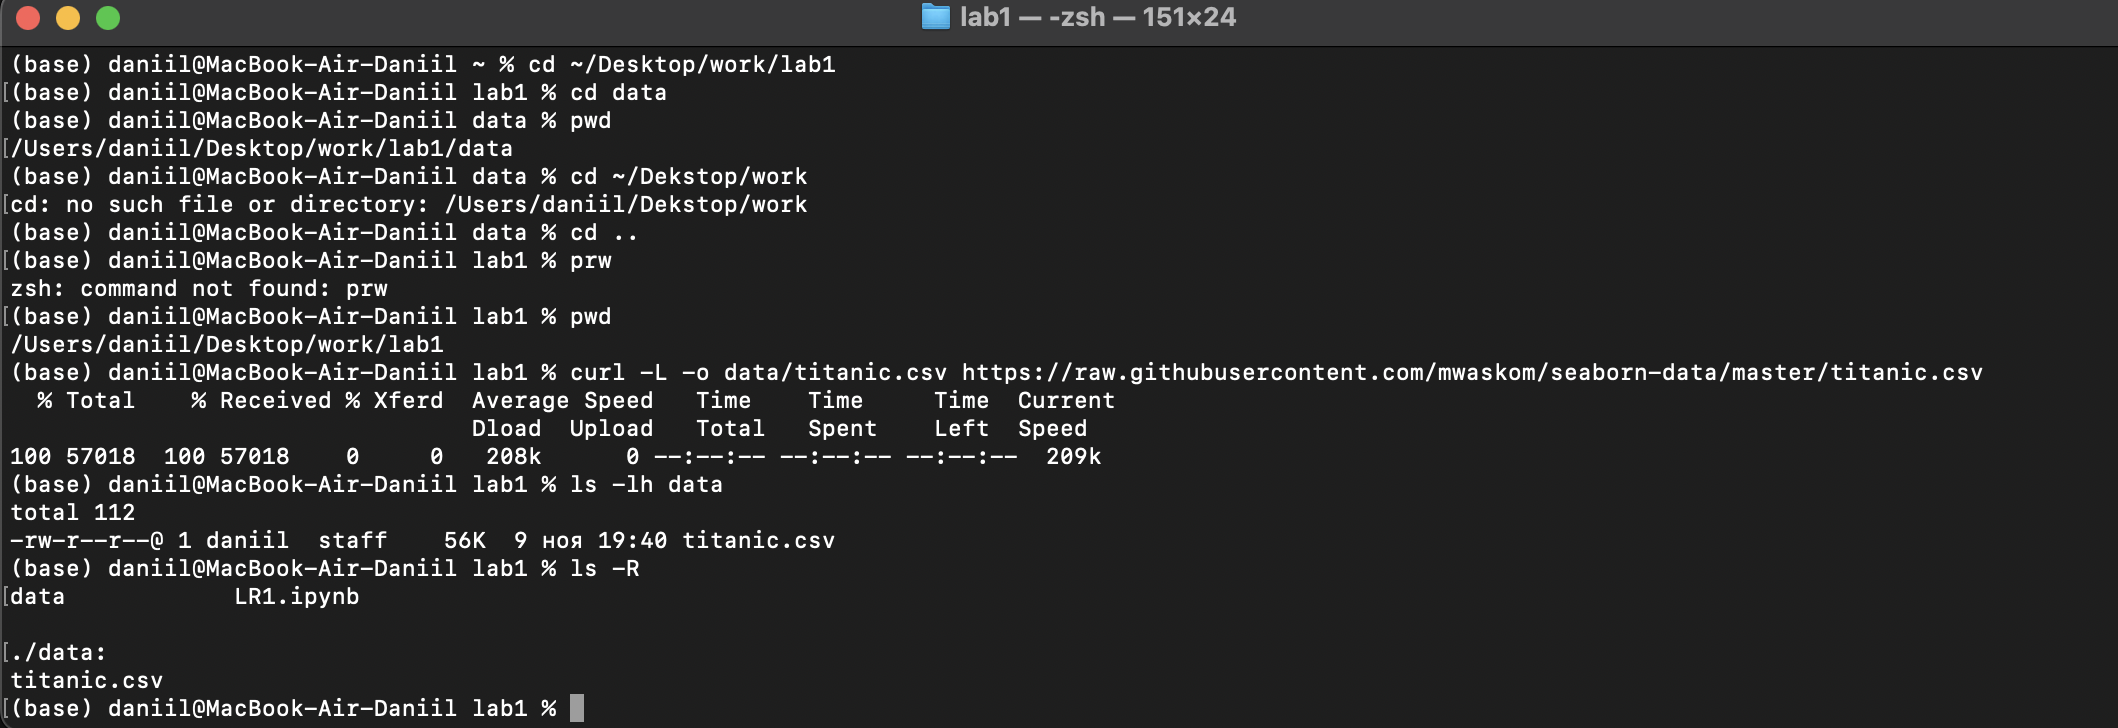

**3.4. Скачать файл `titanic.csv` в папку `data`.**

In [8]:
sh("curl -L -o data/titanic.csv https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 57018  100 57018    0     0   192k      0 --:--:-- --:--:-- --:--:--  193k


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

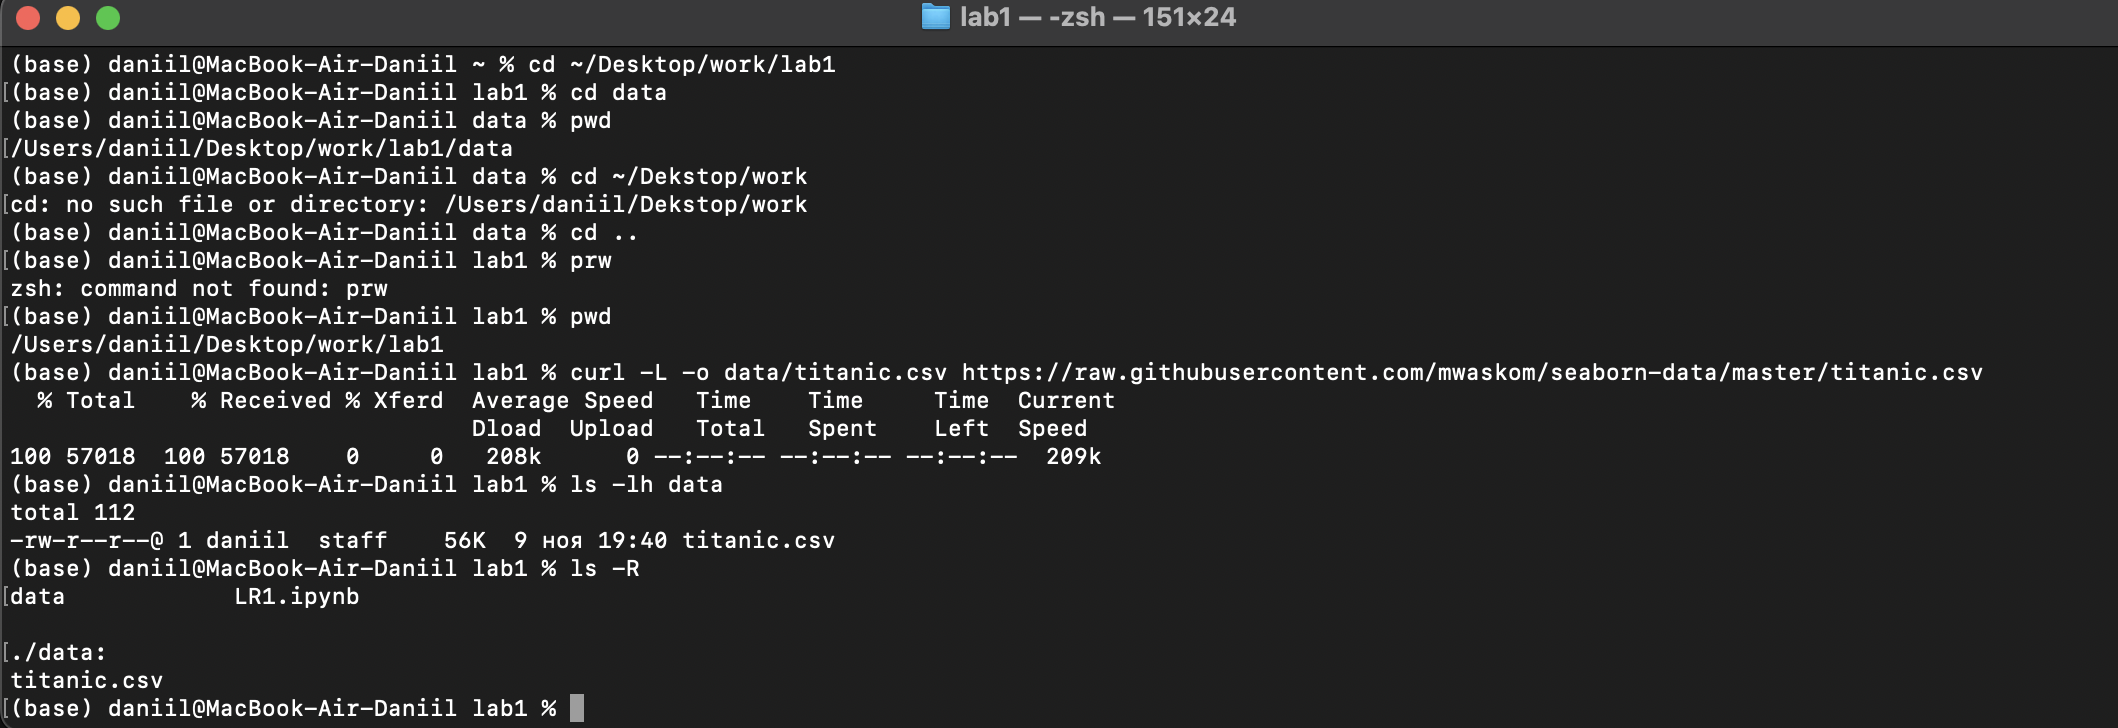

**3.5. Показать содержимое папки `data` с размерами файлов. Дописать команду для своей ОС.**

In [10]:
# Допишите команду (Windows: dir data, macOS и Linux: ls -l data)
sh("ls -l data")

total 112
-rw-r--r--@ 1 daniil  staff  57018 Nov  9 19:36 titanic.csv


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**3.6. Показать структуру проекта.**

In [11]:
sh("tree /f" if WINDOWS else "ls -R")

LR1.ipynb
data

./data:
titanic.csv


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

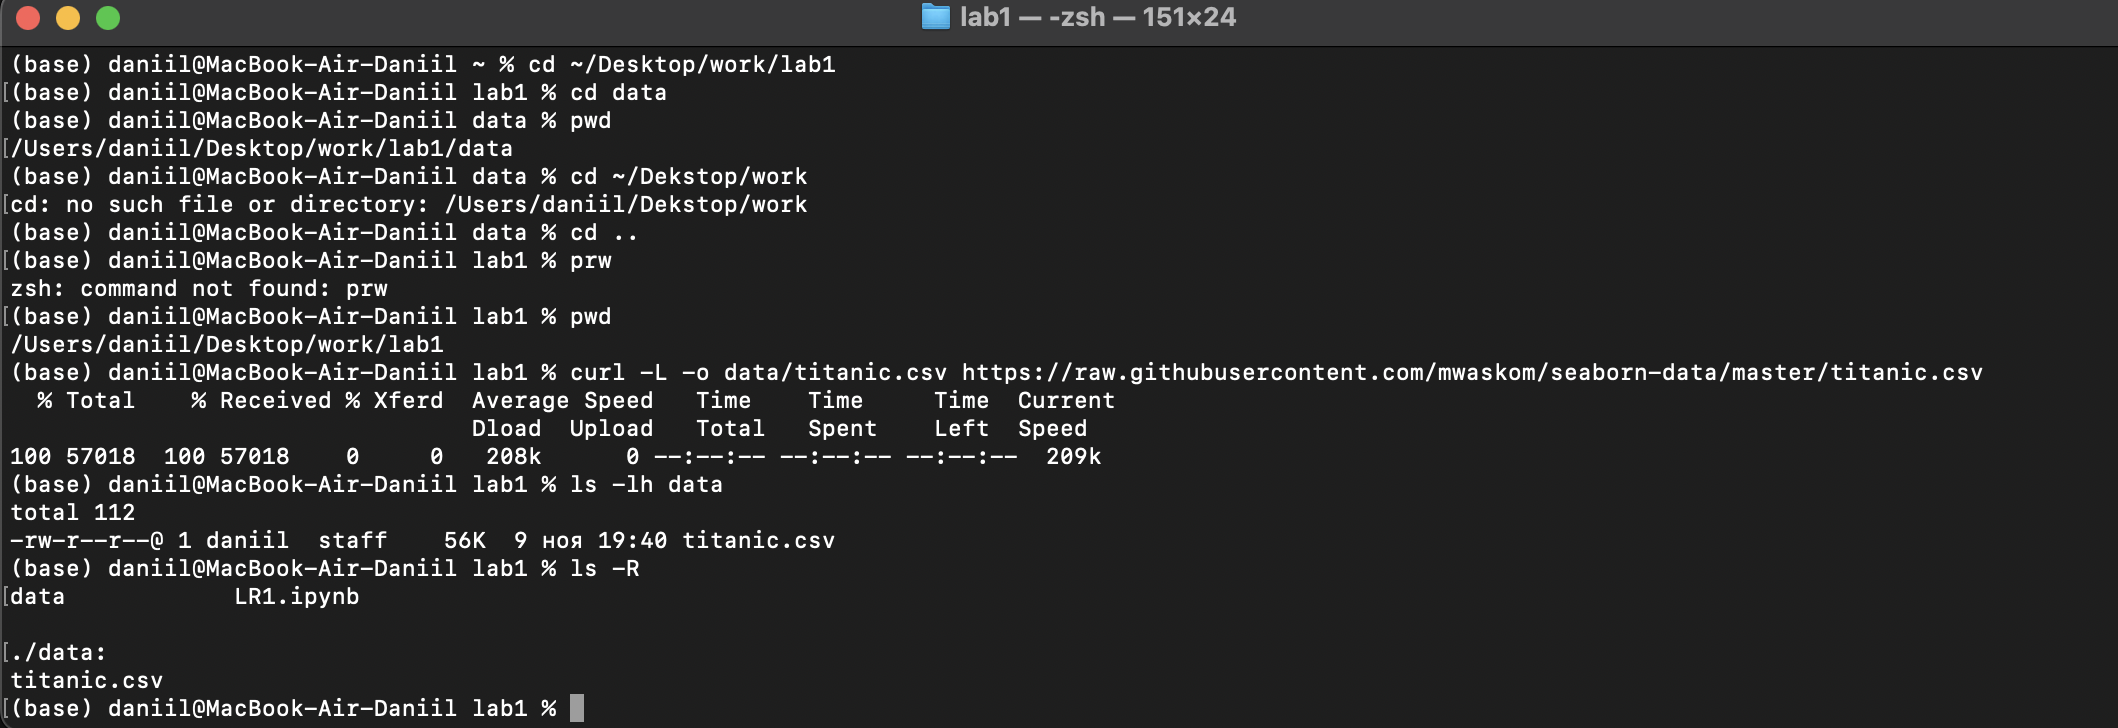

## 4. Git: первая версия проекта

**Цель.** Сохранить проект как версию в системе контроля версий.

Git сохраняет историю изменений проекта и позволяет вернуться к любой версии. Сохраненные версии – основа для публикации работы на GitHub и совместной работы.

**Git** хранит историю проекта как последовательность версий (коммитов), у каждой есть сообщение. Изменения проходят три области: рабочая папка → индекс (`git add`) → репозиторий (`git commit`). Справочник: https://git-scm.com/book/ru/v2

| Команда | Действие |
|---|---|
| `git --version` | проверить установку |
| `git init` | создать репозиторий в указанной папке |
| `git config user.name "Имя Фамилия"` | задать имя автора коммитов |
| `git config user.email "почта"` | задать почту автора (совпадает с почтой GitHub) |
| `git status` | показать состояние: что изменено, что добавлено в индекс |
| `git add .` | добавить в индекс все изменения |
| `git add файл` | добавить в индекс один файл |
| `git commit -m "сообщение"` | сохранить версию |
| `git branch -M main` | назвать основную ветку `main` |
| `git log --oneline` | показать краткую историю версий |

Команды Git одинаковы во всех ОС.

Файл `.gitignore` перечисляет то, что Git не отслеживает:

| Запись | Что исключается |
|---|---|
| `.venv/` | личное виртуальное окружение |
| `__pycache__/` | служебные файлы Python |
| `.ipynb_checkpoints/` | автосохранения ноутбуков |

**4.1. Создать репозиторий в папке дисциплины (на уровень выше `lab1`) и задать имя и почту автора.**

In [13]:
git_name = "Кузовков Даниил Романович"    # Фамилия Имя
git_email = "yt8h7yyg84@privaterelay.appleid.com"   # почта, указанная на GitHub
sh("git init", cwd=COURSE, local=True)
sh(f'git config user.name "{git_name}"', cwd=COURSE, local=True)
sh(f'git config user.email "{git_email}"', cwd=COURSE, local=True)

Reinitialized existing Git repository in /Users/daniil/Desktop/work/.git/


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

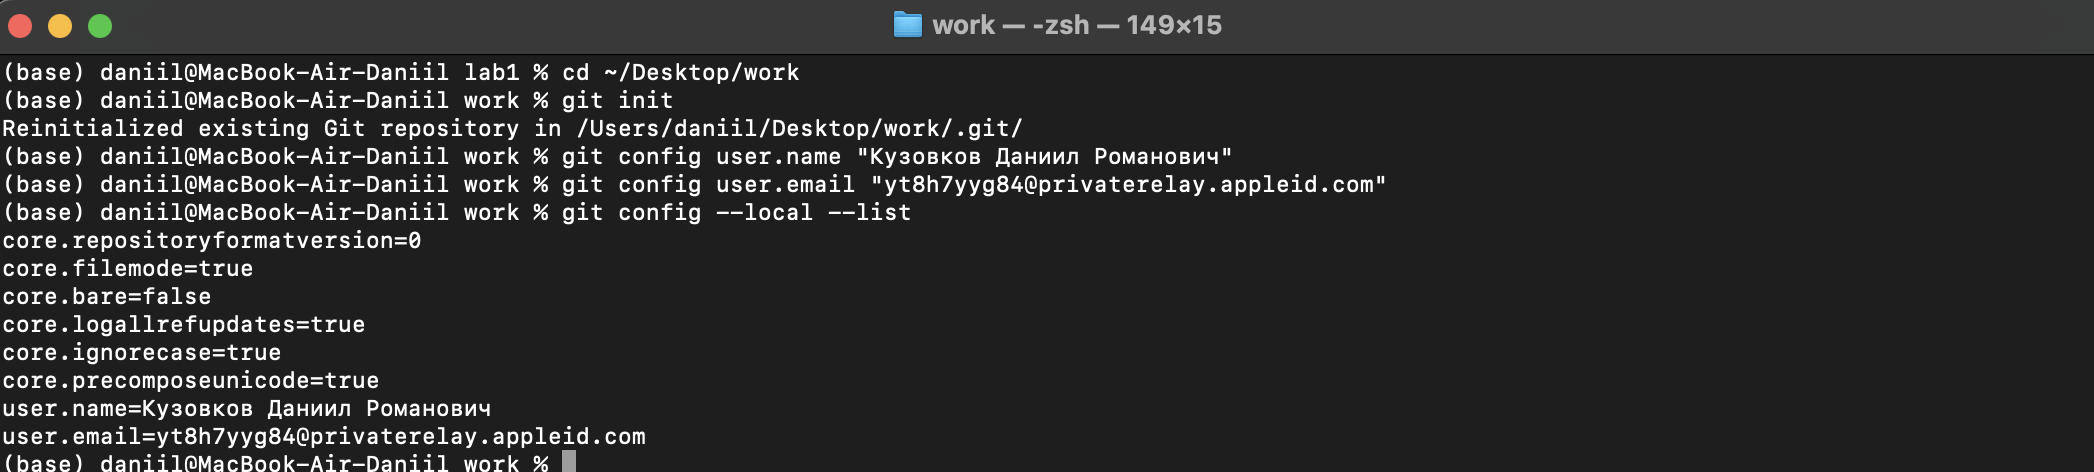

**4.2. Создать файл `.gitignore` и показать его содержимое.**

In [14]:
Path(".gitignore").write_text(".venv/\n__pycache__/\n.ipynb_checkpoints/\n", encoding="utf-8")
sh("type .gitignore" if WINDOWS else "cat .gitignore")

.venv/
__pycache__/
.ipynb_checkpoints/


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

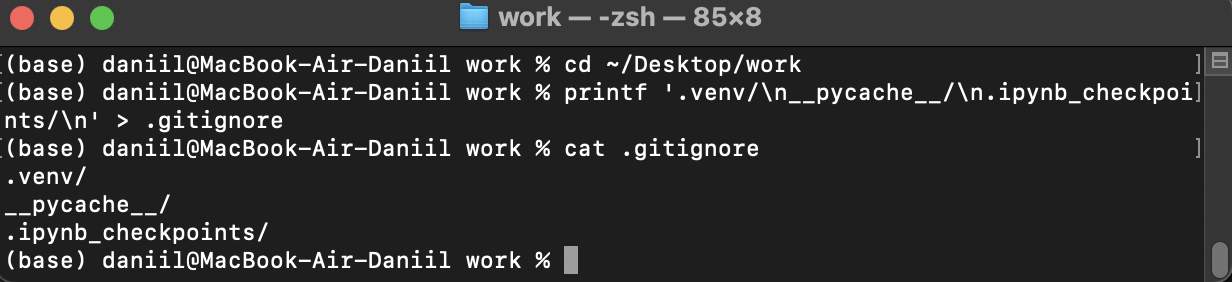

**4.3. Показать состояние репозитория до первого коммита.**

In [15]:
sh("git status", cwd=COURSE, local=True)

On branch main

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.DS_Store
	.gitignore
	lab1/

nothing added to commit but untracked files present (use "git add" to track)


**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

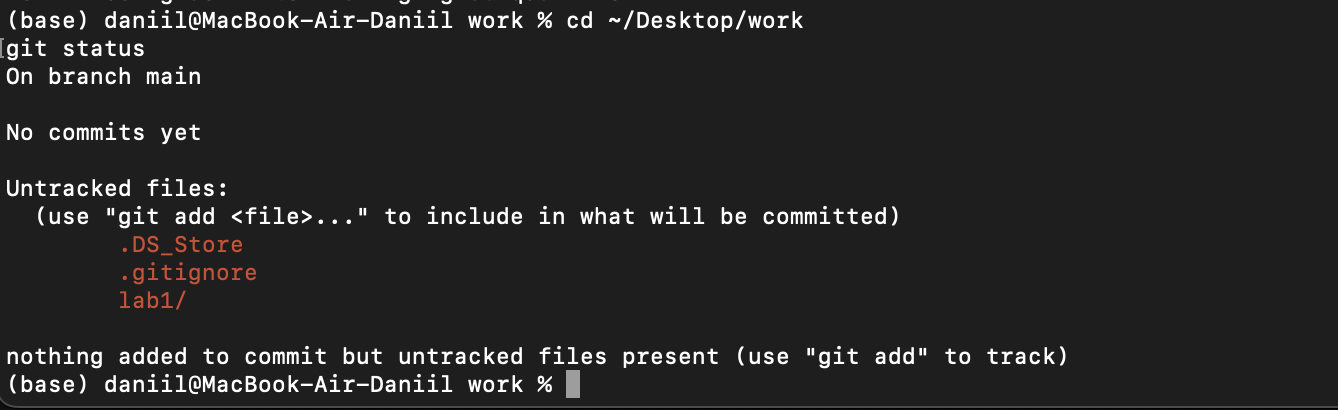

**4.4. Добавить файлы в индекс, сохранить первую версию и назвать основную ветку `main`.**

In [ ]:
sh("git add lab1", cwd=COURSE, local=True)
sh('git commit -m "Добавлена структура проекта и данные"', cwd=COURSE, local=True)
sh("git branch -M main", cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**4.5. Показать историю версий и состояние репозитория после коммита.**

In [ ]:
sh("git log --oneline", cwd=COURSE, local=True)
sh("git status", cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

## 5. Python, виртуальное окружение, pip

**Цель.** Создать изолированное окружение проекта и установить библиотеки.

Виртуальное окружение изолирует библиотеки проекта от других проектов и от системы. Файл `requirements.txt` позволяет воссоздать окружение на другом компьютере.

| Понятие | Что это | Зачем |
|---|---|---|
| Python | язык программирования | на нем написано большинство инструментов для работы с данными |
| Библиотека | готовый набор функций | подключается к программе, чтобы не писать код заново |
| pip | программа установки библиотек | скачивает библиотеки из каталога PyPI (https://pypi.org/) |
| Виртуальное окружение | отдельная копия Python с набором библиотек для одного проекта | версии библиотек разных проектов не конфликтуют |
| `requirements.txt` | список библиотек с версиями | окружение воссоздается на другом компьютере одной командой |

| Библиотека | Назначение | Применение на занятии |
|---|---|---|
| pandas | работа с таблицами | загрузка и просмотр таблицы |
| matplotlib | построение графиков | график в ноутбуке |
| ipykernel | запуск ноутбуков в окружении | необходима для работы ноутбука в окружении проекта |

| Действие | Windows (cmd) | macOS и Linux |
|---|---|---|
| Создать окружение | `python -m venv .venv` | `python3 -m venv .venv` |
| Включить окружение (в терминале) | `.venv\Scripts\activate` | `source .venv/bin/activate` |
| Выключить окружение (в терминале) | `deactivate` | `deactivate` |

В ноутбуке включать окружение не нужно: команды обращаются к программе Python из папки `.venv` напрямую, что равносильно включению. При ручном повторении команд в терминале окружение включается командой из таблицы, затем команды `pip` вводятся без указания пути.

| Команда pip (во всех ОС) | Действие |
|---|---|
| `pip install pandas matplotlib ipykernel` | установить библиотеки |
| `pip list` | показать установленные библиотеки |
| `pip show pandas` | показать сведения о библиотеке |
| `pip freeze > requirements.txt` | сохранить список библиотек с версиями в файл |
| `pip install -r requirements.txt` | установить библиотеки из файла |

**5.1. Создать виртуальное окружение `.venv` в корне проекта.**

In [ ]:
sh(f'"{sys.executable}" -m venv .venv', local=True)
print(VENV_PY)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**5.2. Установить библиотеки pandas, matplotlib и ipykernel в окружение проекта.**

In [ ]:
sh(f'"{VENV_PY}" -m pip install pandas matplotlib ipykernel', local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**5.3. Показать установленные библиотеки и сведения о pandas.**

In [ ]:
sh(f'"{VENV_PY}" -m pip list', local=True)
sh(f'"{VENV_PY}" -m pip show pandas', local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**5.4. Сохранить список библиотек с версиями в `requirements.txt` и показать файл.**

In [ ]:
sh(f'"{VENV_PY}" -m pip freeze > requirements.txt', local=True)
sh("type requirements.txt" if WINDOWS else "cat requirements.txt", local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**5.5. Зафиксировать `requirements.txt` в Git.**

In [ ]:
sh("git add lab1/requirements.txt", cwd=COURSE, local=True)
sh('git commit -m "Добавлен requirements.txt"', cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**5.6. Проверить, что код выполняется в окружении проекта.** 

Перед выполнением выбрать ядро: Select Kernel → Python Environments → `.venv` (если в списке нет, выполнить Developer: Reload Window) и заново выполнить ячейку 0.1.

In [ ]:
print(sys.executable)
print(".venv" in sys.executable)

**5.7. Показать версии библиотек. Дописать пропущенное значение.**

In [ ]:
import pandas, matplotlib, ipykernel

versions = {
    "python": sys.version.split()[0],
    "pandas": pandas.__version__,
    "matplotlib": matplotlib.__version__,
    "ipykernel": "",   # Допишите: версия библиотеки ipykernel (атрибут __version__)
}
versions

## 6. uv как альтернатива pip и venv

**Цель.** Создать окружение и установить библиотеки с помощью uv и сравнить его с pip.

uv решает те же задачи, что venv и pip, но выполняет их быстрее и умеет фиксировать точные версии всех пакетов. Такой инструмент все чаще применяется в современных проектах на Python, поэтому важно понимать, чем он отличается от стандартных.

**uv** – программа для управления окружениями, пакетами и версиями Python, разработанная компанией Astral. Документация: https://docs.astral.sh/uv/

| Показатель | pip и venv | uv |
|---|---|---|
| Состав | две отдельные программы: venv создает окружение, pip устанавливает библиотеки | одна программа: окружения, библиотеки, проекты, версии Python |
| Установка | входит в поставку Python | устанавливается отдельно |
| Скорость | ниже | выше (параллельная загрузка, общий кэш пакетов) |
| Фиксация версий | `requirements.txt`: версии установленных пакетов | `pyproject.toml` и `uv.lock`: зависимости проекта и точные версии всех пакетов |
| Версия Python | используется установленная в системе | `uv python install 3.12` загружает нужную версию |

| Действие | pip и venv | uv |
|---|---|---|
| Создать окружение | `python -m venv .venv` | `uv venv .venv` |
| Установить библиотеки | `pip install pandas` | `uv pip install pandas` |
| Показать библиотеки | `pip list` | `uv pip list` |
| Сохранить список | `pip freeze > requirements.txt` | `uv pip freeze > requirements.txt` |
| Установить из списка | `pip install -r requirements.txt` | `uv pip install -r requirements.txt` |

Интерфейс `uv pip` повторяет команды pip. Кроме него, uv имеет проектный режим: `uv init` создает проект, `uv add pandas` добавляет библиотеку в `pyproject.toml` и `uv.lock`, `uv sync` воссоздает окружение по этим файлам, `uv run файл.py` запускает программу в окружении проекта. Руководство: https://docs.astral.sh/uv/guides/projects/

Установка uv отдельной программой: https://docs.astral.sh/uv/getting-started/installation/ В ноутбуке uv устанавливается в окружение проекта командой `pip`, а запускается как `python -m uv`.

**6.1. Установить uv в окружение проекта. Это необходимо, так как uv не входит в поставку Python.**

In [ ]:
sh(f'"{VENV_PY}" -m pip install uv', local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**6.2. Показать версию uv, чтобы убедиться в установке.**

In [ ]:
sh(f"{UV} --version", local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**6.3. Добавить `.venv-uv/` в `.gitignore`: окружение личное и не должно попадать в репозиторий.**

In [ ]:
gitignore = Path(".gitignore")
text = gitignore.read_text(encoding="utf-8")
if ".venv-uv/" not in text:
    gitignore.write_text(text + ".venv-uv/\n", encoding="utf-8")
print(gitignore.read_text(encoding="utf-8"))

**6.4. Создать второе окружение `.venv-uv` командой uv. Сравнить с шагом 5.1: назначение то же, команда другая.**

In [ ]:
sh(f"{UV} venv .venv-uv", local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**6.5. Установить библиотеки в окружение `.venv-uv`. Путь к окружению задается параметром `--python`.**

In [ ]:
sh(f'{UV} pip install --python "{UVENV_PY}" pandas matplotlib ipykernel', local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**6.6. Показать библиотеки окружения `.venv-uv`. Список совпадает с `pip list` окружения `.venv`.**

In [ ]:
sh(f'{UV} pip list --python "{UVENV_PY}"', local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**6.7. Измерить время создания окружения и установки библиотек pip и uv во временных папках. Сравнить результаты.**

In [ ]:
import time, shutil

def timed(command):
    start = time.perf_counter()
    subprocess.run(command, shell=True, cwd=ROOT, capture_output=True, stdin=subprocess.DEVNULL)
    return time.perf_counter() - start

if IN_COLAB:
    print("Пропущено")
else:
    libs = "pandas matplotlib"
    tmp_pip, tmp_uv = ROOT / ".tmp-pip", ROOT / ".tmp-uv"
    t_pip = timed(f'"{sys.executable}" -m venv "{tmp_pip}"') + timed(f'"{venv_python(tmp_pip)}" -m pip install {libs}')
    t_uv = timed(f'{UV} venv "{tmp_uv}"') + timed(f'{UV} pip install --python "{venv_python(tmp_uv)}" {libs}')
    print(f"pip и venv: {t_pip:.1f} с")
    print(f"uv:         {t_uv:.1f} с")
    shutil.rmtree(tmp_pip, ignore_errors=True)
    shutil.rmtree(tmp_uv, ignore_errors=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

## 7. Первая работа с таблицей

**Цель.** Загрузить таблицу, вывести ее первые строки и размер, построить график. Задача блока – проверить, что библиотеки работают; содержательный разбор данных не проводится.

Загрузка и просмотр таблицы – простейшая проверка того, что окружение работает и библиотеки установлены. Те же действия лежат в основе дальнейшей работы с данными на курсе.

| Функция | Для чего |
|---|---|
| `pd.read_csv(путь)` | прочитать CSV-файл в таблицу (DataFrame) |
| `df.head(n)` | вывести первые `n` строк (по умолчанию 5) |
| `df.shape` | размер таблицы: (число строк, число столбцов) |
| `df["столбец"]` | выбрать один столбец |
| `.plot(kind="hist", bins=N)` | гистограмма из `N` интервалов (matplotlib) |
| `plt.title`, `plt.xlabel`, `plt.ylabel` | заголовок и подписи осей |
| `plt.show()` | показать график |
| `Path(путь).exists()` | проверить, существует ли файл |

После выполнения всех ячеек проверить воспроизводимость: Restart, затем Run All; все ячейки должны выполниться без ошибок.

**7.1. Загрузить таблицу из файла `data/titanic.csv` (или по ссылке) и вывести первые строки.**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

LOCAL = ROOT / "data" / "titanic.csv"
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)
df.head()

**7.2. Вывести размер таблицы (число строк и столбцов). Дописать код.**

In [ ]:
# Допишите: вывести размер таблицы (число строк и столбцов)
print()

**7.3. Построить гистограмму столбца `age`. Выполнить самостоятельно.**

In [ ]:
# Самостоятельно: построить гистограмму столбца age с заголовком и подписями осей

**7.4. Построить гистограмму столбца `fare` с заголовком и подписями осей. Выполнить самостоятельно.**

In [ ]:
# Самостоятельно: построить гистограмму столбца fare с заголовком и подписями осей

**Описание работы.** Написать 3–4 предложения собственными словами: какие библиотеки подключены, что делает каждая ячейка, что изображено на графике (оси и единицы измерения).

**7.5. Сохранить ноутбук (Ctrl + S) и зафиксировать версию в Git.**

In [ ]:
sh("git add lab1/notebooks/lab1.ipynb lab1/.gitignore", cwd=COURSE, local=True)
sh('git commit -m "Добавлена работа с таблицей"', cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

## 8. GitHub: проект в интернете

**Цель.** Разместить проект в интернете и связать его с локальным репозиторием.

GitHub делает проект доступным в интернете и хранит его историю. Публичный репозиторий будет применяться для сдачи некоторых работ в курсе, а также для запуска этого ноутбука в облаке позже.

| Элемент GitHub | Для чего |
|---|---|
| New repository (https://github.com/new) | создание репозитория дисциплины (на все занятия курса) |
| Public | репозиторий доступен всем: это необходимо для показа работы и запуска ноутбука в облаке |
| README | титульная страница проекта: автор, содержимое, порядок запуска |
| Add README / Add .gitignore / Choose a license | не отмечать: репозиторий создается пустым; эти файлы появятся после отправки |
| папка `lab1` | занятие внутри репозитория дисциплины: на компьютере уже есть, на GitHub появится после отправки |

| Команда Git | Действие |
|---|---|
| `git remote add origin ссылка` | связать локальный репозиторий с удаленным |
| `git push -u origin main` | отправить версии на GitHub и запомнить связь |
| `git pull` | получить изменения из удаленного репозитория |
| `git clone ссылка` | скопировать удаленный репозиторий на компьютер |

| Признак | Причина | Решение |
|---|---|---|
| `could not read Username` или `Authentication failed` при отправке из ячейки | Git не может открыть окно входа из ячейки | открыть Source Control (Ctrl + Shift + G, macOS: Cmd + Shift + G), нажать Sync Changes или Publish Branch и войти через GitHub в браузере; затем повторить `git push` |
| `remote origin already exists` | связь уже создана | проверить адрес: `git remote -v` |
| GitHub не принимает пароль | пароль для Git не поддерживается | использовать вход через браузер |

Перед выполнением ячеек создать репозиторий дисциплины на GitHub: Public, без README, `.gitignore` и лицензии. Имя репозитория записать в ячейке 8.2. Папка `lab1` уже есть на компьютере и появится в репозитории после отправки. При первой отправке войти в GitHub через браузер.

**8.1. Создать файл `README.md` в папке `lab1` и зафиксировать версию.**

In [ ]:
readme = rf"""# Практическое занятие 1. Рабочее окружение

Автор: {student}, группа {group}

## Структура папки lab1

Папка data содержит данные, папка notebooks – ноутбук lab1.ipynb, файл requirements.txt – список библиотек.

## Запуск на локальном компьютере

В папке lab1:

1. Создать окружение: python -m venv .venv
2. Включить окружение: .venv\Scripts\activate (macOS и Linux: source .venv/bin/activate)
3. Установить библиотеки: pip install -r requirements.txt
4. Открыть notebooks/lab1.ipynb в VS Code и выбрать ядро .venv
"""
Path("README.md").write_text(readme, encoding="utf-8")
sh("git add lab1/README.md", cwd=COURSE, local=True)
sh('git commit -m "Добавлен README"', cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**8.2. Связать локальный репозиторий дисциплины с репозиторием на GitHub и проверить адрес. Записать имя созданного репозитория.**

In [ ]:
repo = ""   # имя репозитория дисциплины на GitHub
sh(f"git remote add origin https://github.com/{github_username}/{repo}.git", cwd=COURSE, local=True)
sh("git remote -v", cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**8.3. Отправить версии на GitHub.**

После выполнения обновить страницу репозитория: в репозитории должна быть папка `lab1`, а в ней `README.md`, `requirements.txt`, `.gitignore`, папки `data` и `notebooks`; папок `.venv` и `.venv-uv` быть не должно.

In [ ]:
sh("git push -u origin main", cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**Скриншот.** Страница репозитория на GitHub: в списке видна папка `lab1`; страница папки `lab1` со списком файлов и оформленным README; адрес в адресной строке браузера.

## 9. Colab: запуск из репозитория

**Цель.** Запустить ноутбук из репозитория в облаке и сравнить две среды.

Запуск ноутбука из репозитория в облачной среде показывает, что проект воспроизводится без установки программ на компьютер. Сравнение двух сред выявляет, что определяет результат выполнения: версии библиотек, наличие файлов, настройка.

| Способ открыть ноутбук из GitHub в Colab | Как |
|---|---|
| По адресу | `https://colab.research.google.com/github/имя_пользователя/репозиторий/blob/main/путь_к_файлу.ipynb` |
| Через меню | File → Open notebook → вкладка GitHub |
| Кнопкой в README | значок Open In Colab со ссылкой на ноутбук |

Изменения, сделанные в Colab, в репозиторий не попадают: сохранить их на GitHub можно через File → Save a copy in GitHub. 

Если Colab предупреждает, что ноутбук создан не Google, нажать Run anyway. Ячейки с командами Git и окружения в Colab пропускаются автоматически.

**9.1. Сформировать адрес ноутбука в Colab. Открыть адрес в браузере и выполнить Runtime → Run all.**

In [ ]:
colab_url = f"https://colab.research.google.com/github/{github_username}/{repo}/blob/main/lab1/notebooks/lab1.ipynb"
print(colab_url)

**9.2. Показать сведения о pandas. Выполнить ячейку в Colab и в VS Code, заполнить таблицу сравнения ниже.**

In [ ]:
%pip show pandas

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

| | VS Code | Colab |
|---|---|---|
| Версия Python | | |
| Версия pandas | | |
| Где хранятся файлы | | |
| Что потребовалось для запуска | | |

**Скриншот.** Ноутбук в Colab после Run all: в адресной строке виден адрес вида `github/имя_пользователя/имя_репозитория/blob/main/lab1`, выведены таблица и график.

## 10. Задания на дом

**Цель.** Закрепить пройденное и проверить, что проект воспроизводится из репозитория.

Воссоздание проекта на чистой папке показывает, что в репозитории есть все необходимое для запуска. Остальные задания завершают работу, не выполненную на занятии.

1. Воссоздать окружение из репозитория ячейками 10.1 и 10.2. Версия pandas должна совпадать с указанной в `requirements.txt`.
2. Дополнить `README.md` кнопкой запуска в Colab (ячейка 10.3) и таблицей сравнения из блока 9, отправить изменения. Кнопка:
   ```
   [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](ссылка_на_ноутбук_в_Colab)
   ```
3. Пройти тренажер Git: https://learngitbranching.js.org/ (раздел Main, серия Introduction Sequence).
4. Найти в документации pandas функцию, выводящую последние строки таблицы, и применить ее в ячейке 10.4.

**10.1. Склонировать репозиторий дисциплины рядом с рабочей папкой, создать окружение в его папке `lab1`, установить библиотеки из `requirements.txt` и вывести версию pandas.**

In [ ]:
CHECK = COURSE.parent / f"{repo}_check"
LAB = CHECK / "lab1"
sh(f'git clone https://github.com/{github_username}/{repo}.git "{CHECK}"', cwd=COURSE.parent, local=True)
sh(f'"{sys.executable}" -m venv .venv', cwd=LAB, local=True)
sh(f'"{venv_python(LAB / ".venv")}" -m pip install -r requirements.txt', cwd=LAB, local=True)
sh(f'"{venv_python(LAB / ".venv")}" -c "import pandas; print(pandas.__version__)"', cwd=LAB, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**10.2. Удалить проверочную копию.**

In [ ]:
# Удалить проверочную копию после проверки
import shutil
if not IN_COLAB and CHECK.exists():
    shutil.rmtree(CHECK)
    print("Удалено:", CHECK)

**10.3. Дополнить `README.md` кнопкой запуска в Colab, зафиксировать версию и отправить на GitHub. Дописать сообщение коммита.**

In [ ]:
# Дополнить README.md кнопкой запуска в Colab
badge = f"[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)]({colab_url})"
text = Path("README.md").read_text(encoding="utf-8")
if badge not in text:
    Path("README.md").write_text(badge + "\n\n" + text, encoding="utf-8")
sh("git add lab1/README.md", cwd=COURSE, local=True)
sh('git commit -m ""', cwd=COURSE, local=True)   # Допишите сообщение коммита
sh("git push", cwd=COURSE, local=True)

**Скриншот.** Выполнить те же команды вручную в терминале на своем компьютере и вставить скриншот результата.

**10.4. Вывести последние 3 строки таблицы. Дописать код.**

In [ ]:
# Допишите: вывести последние 3 строки таблицы

**Скриншот.** Задание 4: страница тренажера с пройденными уровнями.

## Справочные ресурсы

| Ресурс | Для чего | Адрес |
|---|---|---|
| Pro Git (на русском) | справочник по Git | https://git-scm.com/book/ru/v2 |
| Тренажер Git | отработка команд Git в браузере | https://learngitbranching.js.org/ |
| Документация GitHub | работа с репозиториями | https://docs.github.com/ru |
| Каталог PyPI | поиск библиотек Python | https://pypi.org/ |
| Документация venv | виртуальные окружения | https://docs.python.org/3/library/venv.html |
| Документация pip | установка библиотек | https://pip.pypa.io/en/stable/ |
| Документация uv | окружения, библиотеки и проекты | https://docs.astral.sh/uv/ |
| Документация pandas | функции для работы с таблицами | https://pandas.pydata.org/docs/ |
| Документация matplotlib | построение графиков | https://matplotlib.org/stable/ |
| Документация Jupyter в VS Code | работа с ноутбуками | https://code.visualstudio.com/docs/datascience/jupyter-notebooks |
| Основы Markdown | оформление текстовых ячеек и README | https://www.markdownguide.org/basic-syntax/ |